In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.impute import SimpleImputer


# 0) Reproducibility

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)


In [ ]:
import pandas as pd

df = pd.read_csv("Automobile_price_data_Raw_set.csv")

features = [
    "body-style",
    "wheel-base",
    "engine-size",
    "horsepower",
    "peak-rpm",
    "highway-mpg",
    "price"
]

target = "make"

df = df[features + [target]]
df.head()


,body-style,wheel-base,engine-size,horsepower,peak-rpm,highway-mpg,price,make
0,convertible,88.6,130,111.0,5000.0,27,13495.0,alfa-romero
1,convertible,88.6,130,111.0,5000.0,27,16500.0,alfa-romero
2,hatchback,94.5,152,154.0,5000.0,26,16500.0,alfa-romero
3,sedan,99.8,109,102.0,5500.0,30,13950.0,audi
4,sedan,99.4,136,115.0,5500.0,22,17450.0,audi


In [ ]:
df = df.dropna(subset=["make"]).copy()

In [ ]:
num_cols = [
    "wheel-base", "engine-size", "horsepower",
    "peak-rpm", "highway-mpg", "price"
]
cat_cols = ["body-style"]

num_imputer = SimpleImputer(strategy="median")
cat_imputer = SimpleImputer(strategy="most_frequent")

df[num_cols] = num_imputer.fit_transform(df[num_cols])
df[cat_cols] = cat_imputer.fit_transform(df[cat_cols])
df

,body-style,wheel-base,engine-size,horsepower,peak-rpm,highway-mpg,price,make
0,convertible,88.6,130.0,111.0,5000.0,27.0,13495.0,alfa-romero
1,convertible,88.6,130.0,111.0,5000.0,27.0,16500.0,alfa-romero
2,hatchback,94.5,152.0,154.0,5000.0,26.0,16500.0,alfa-romero
3,sedan,99.8,109.0,102.0,5500.0,30.0,13950.0,audi
4,sedan,99.4,136.0,115.0,5500.0,22.0,17450.0,audi
...,...,...,...,...,...,...,...,...
200,sedan,109.1,141.0,114.0,5400.0,28.0,16845.0,volvo
201,sedan,109.1,141.0,160.0,5300.0,25.0,19045.0,volvo
202,sedan,109.1,173.0,134.0,5500.0,23.0,21485.0,volvo
203,sedan,109.1,145.0,106.0,4800.0,27.0,22470.0,volvo


In [ ]:
df = pd.get_dummies(df, columns=['body-style'], drop_first=True)
for col in df.columns:
    if df[col].dtype == 'bool':
        df[col] = df[col].astype(int)
df

,wheel-base,engine-size,horsepower,peak-rpm,highway-mpg,price,make,body-style_hardtop,body-style_hatchback,body-style_sedan,body-style_wagon
0,88.6,130.0,111.0,5000.0,27.0,13495.0,alfa-romero,0,0,0,0
1,88.6,130.0,111.0,5000.0,27.0,16500.0,alfa-romero,0,0,0,0
2,94.5,152.0,154.0,5000.0,26.0,16500.0,alfa-romero,0,1,0,0
3,99.8,109.0,102.0,5500.0,30.0,13950.0,audi,0,0,1,0
4,99.4,136.0,115.0,5500.0,22.0,17450.0,audi,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...
200,109.1,141.0,114.0,5400.0,28.0,16845.0,volvo,0,0,1,0
201,109.1,141.0,160.0,5300.0,25.0,19045.0,volvo,0,0,1,0
202,109.1,173.0,134.0,5500.0,23.0,21485.0,volvo,0,0,1,0
203,109.1,145.0,106.0,4800.0,27.0,22470.0,volvo,0,0,1,0


In [ ]:
df['make'].value_counts()

,count
make,
toyota,31
nissan,18
mazda,17
honda,13
mitsubishi,12
subaru,12
volkswagen,12
volvo,11
peugot,11


In [ ]:
makes_to_drop = [
    'isuzu',
    'alfa-romero',
   'chevrolet',
    'jaguar',
    'renault',
    'mercury'
]
df = df[~df['make'].isin(makes_to_drop)]
df

,wheel-base,engine-size,horsepower,peak-rpm,highway-mpg,price,make,body-style_hardtop,body-style_hatchback,body-style_sedan,body-style_wagon
3,99.8,109.0,102.0,5500.0,30.0,13950.0,audi,0,0,1,0
4,99.4,136.0,115.0,5500.0,22.0,17450.0,audi,0,0,1,0
5,99.8,136.0,110.0,5500.0,25.0,15250.0,audi,0,0,1,0
6,105.8,136.0,110.0,5500.0,25.0,17710.0,audi,0,0,1,0
8,105.8,131.0,140.0,5500.0,20.0,23875.0,audi,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...
200,109.1,141.0,114.0,5400.0,28.0,16845.0,volvo,0,0,1,0
201,109.1,141.0,160.0,5300.0,25.0,19045.0,volvo,0,0,1,0
202,109.1,173.0,134.0,5500.0,23.0,21485.0,volvo,0,0,1,0
203,109.1,145.0,106.0,4800.0,27.0,22470.0,volvo,0,0,1,0


In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y = le.fit_transform(df["make"])          # integer labels 0..C-1
X = df.drop(columns=["make"]).copy()      # features DataFrame

print("X shape:", X.shape)
print("Num classes:", len(le.classes_))


X shape: (185, 10)
Num classes: 16


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train:", X_train.shape, "Test:", X_test.shape)


Train: (148, 10) Test: (37, 10)


In [ ]:
from sklearn.preprocessing import StandardScaler

num_cols = ["wheel-base", "engine-size", "horsepower", "peak-rpm", "highway-mpg", "price"]

scaler = StandardScaler()
X_train.loc[:, num_cols] = scaler.fit_transform(X_train[num_cols])
X_test.loc[:, num_cols]  = scaler.transform(X_test[num_cols])


In [ ]:
import numpy as np

X_train_np = X_train.to_numpy(dtype=np.float32)
X_test_np  = X_test.to_numpy(dtype=np.float32)

y_train_np = y_train.astype(np.int32)
y_test_np  = y_test.astype(np.int32)

input_dim = X_train_np.shape[1]
num_classes = len(np.unique(y_train_np))

print("input_dim:", input_dim, "num_classes:", num_classes)

input_dim: 10 num_classes: 16


In [ ]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train_np)
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train_np)
class_weight = dict(zip(classes, weights))

class_weight

{np.int32(0): np.float64(1.85),
 np.int32(1): np.float64(1.5416666666666667),
 np.int32(2): np.float64(1.5416666666666667),
 np.int32(3): np.float64(0.925),
 np.int32(4): np.float64(0.6607142857142857),
 np.int32(5): np.float64(1.5416666666666667),
 np.int32(6): np.float64(0.925),
 np.int32(7): np.float64(0.6607142857142857),
 np.int32(8): np.float64(1.0277777777777777),
 np.int32(9): np.float64(1.85),
 np.int32(10): np.float64(2.3125),
 np.int32(11): np.float64(1.85),
 np.int32(12): np.float64(0.925),
 np.int32(13): np.float64(0.37),
 np.int32(14): np.float64(0.925),
 np.int32(15): np.float64(1.0277777777777777)}

In [ ]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.regularizers import l2

tf.keras.backend.clear_session()

model = Sequential([

    Dense(128, activation="relu", input_shape=(input_dim,), kernel_regularizer=l2(1e-3)),
    BatchNormalization(),
    Dropout(0.1),

    Dense(64, activation="relu", kernel_regularizer=l2(1e-3)),
    BatchNormalization(),
    Dropout(0.1),

    Dense(32, activation="relu", kernel_regularizer=l2(1e-3)),
    Dropout(0.1),

    Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=5e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         1,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           528 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,040 (50.94 KB)

 Trainable params: 12,656 (49.44 KB)

 Non-trainable params: 384 (1.50 KB)

In [ ]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=60,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=8,
        min_lr=1e-5
    )
]

history = model.fit(
    X_train_np, y_train_np,
    validation_split=0.2,
    epochs=500,
    batch_size=16,
    class_weight=class_weight,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/500
8/8 ━━━━━━━━━━━━━━━━━━━━ 5s 103ms/step - accuracy: 0.0566 - loss: 3.3968 - val_accuracy: 0.1667 - val_loss: 2.8602 - learning_rate: 5.0000e-04
Epoch 2/500
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.0855 - loss: 3.0398 - val_accuracy: 0.1667 - val_loss: 2.8545 - learning_rate: 5.0000e-04
Epoch 3/500
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.1896 - loss: 2.7656 - val_accuracy: 0.2000 - val_loss: 2.8487 - learning_rate: 5.0000e-04
Epoch 4/500
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.1502 - loss: 2.6128 - val_accuracy: 0.2667 - val_loss: 2.8412 - learning_rate: 5.0000e-04
Epoch 5/500
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.3246 - loss: 2.4136 - val_accuracy: 0.2667 - val_loss: 2.8347 - learning_rate: 5.0000e-04
Epoch 6/500
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3466 - loss: 2.3305 - val_accuracy: 0.2333 - val_loss: 2.8271 - learning_rate: 5.0000e-04
Epoch 7/500
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.2684 - loss

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, classification_report
import numpy as np

y_prob = model.predict(X_test_np)
y_pred = np.argmax(y_prob, axis=1)

# Get the unique labels present in the test set
actual_labels_in_test_set = np.unique(y_test_np)

# Filter le.classes_ to match the actual labels in the test set
target_names_for_report = le.inverse_transform(actual_labels_in_test_set)

print("Accuracy:", accuracy_score(y_test_np, y_pred))
print("Macro F1:", f1_score(y_test_np, y_pred, average="macro"))
print(classification_report(y_test_np, y_pred, labels=actual_labels_in_test_set, target_names=target_names_for_report))


1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step
Accuracy: 0.5675675675675675
Macro F1: 0.5959325396825397
               precision    recall  f1-score   support

         audi       1.00      1.00      1.00         1
          bmw       1.00      1.00      1.00         2
        dodge       0.00      0.00      0.00         2
        honda       0.75      1.00      0.86         3
        mazda       0.40      0.67      0.50         3
mercedes-benz       1.00      1.00      1.00         2
   mitsubishi       0.00      0.00      0.00         2
       nissan       1.00      0.50      0.67         4
       peugot       1.00      1.00      1.00         2
     plymouth       0.33      0.50      0.40         2
      porsche       1.00      1.00      1.00         1
         saab       0.50      1.00      0.67         1
       subaru       0.50      0.50      0.50         2
       toyota       0.67      0.33      0.44         6
   volkswagen       0.00      0.00      0.00         2
        volvo       0.5

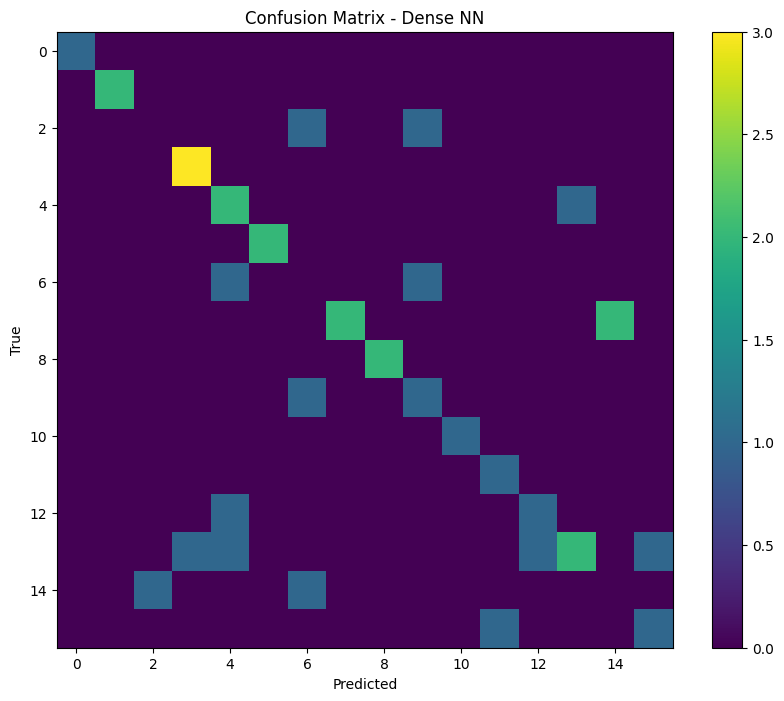

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test_np, y_pred)

plt.figure(figsize=(10,8))
plt.imshow(cm, interpolation="nearest")
plt.title("Confusion Matrix - Dense NN")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.colorbar()
plt.show()


In [ ]:
import pandas as pd

new_samples = pd.DataFrame([
    ['sedan',     103.5, 164, 121, 4250, 25, 24565],
    ['hatchback',  86.6,  92,  58, 4800, 54,  6479]
], columns=[
    'body-style',
    'wheel-base',
    'engine-size',
    'horsepower',
    'peak-rpm',
    'highway-mpg',
    'price'
])

new_samples


,body-style,wheel-base,engine-size,horsepower,peak-rpm,highway-mpg,price
0,sedan,103.5,164,121,4250,25,24565
1,hatchback,86.6,92,58,4800,54,6479


In [ ]:
# One-hot encode
new_samples_enc = pd.get_dummies(new_samples, columns=['body-style'])

# Align with training feature columns
new_samples_enc = new_samples_enc.reindex(
    columns=X_train.columns,
    fill_value=0
)


In [ ]:
num_cols = [
    "wheel-base", "engine-size", "horsepower",
    "peak-rpm", "highway-mpg", "price"
]

new_samples_enc[num_cols] = scaler.transform(new_samples_enc[num_cols])


In [ ]:
import numpy as np

X_new = new_samples_enc.to_numpy(dtype=np.float32)


In [ ]:
y_prob = model.predict(X_new)
y_pred = np.argmax(y_prob, axis=1)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


In [ ]:
predicted_makes = le.inverse_transform(y_pred)

predicted_makes


array(['bmw', 'honda'], dtype=object)

In [ ]:
top_k = 3

for i, probs in enumerate(y_prob):
    top_idx = probs.argsort()[::-1][:top_k]
    print(f"\nSample {i+1}")
    for idx in top_idx:
        print(f"  {le.inverse_transform([idx])[0]}: {probs[idx]:.3f}")



Sample 1
  bmw: 0.915
  mercedes-benz: 0.024
  peugot: 0.018

Sample 2
  honda: 0.835
  toyota: 0.088
  audi: 0.027
